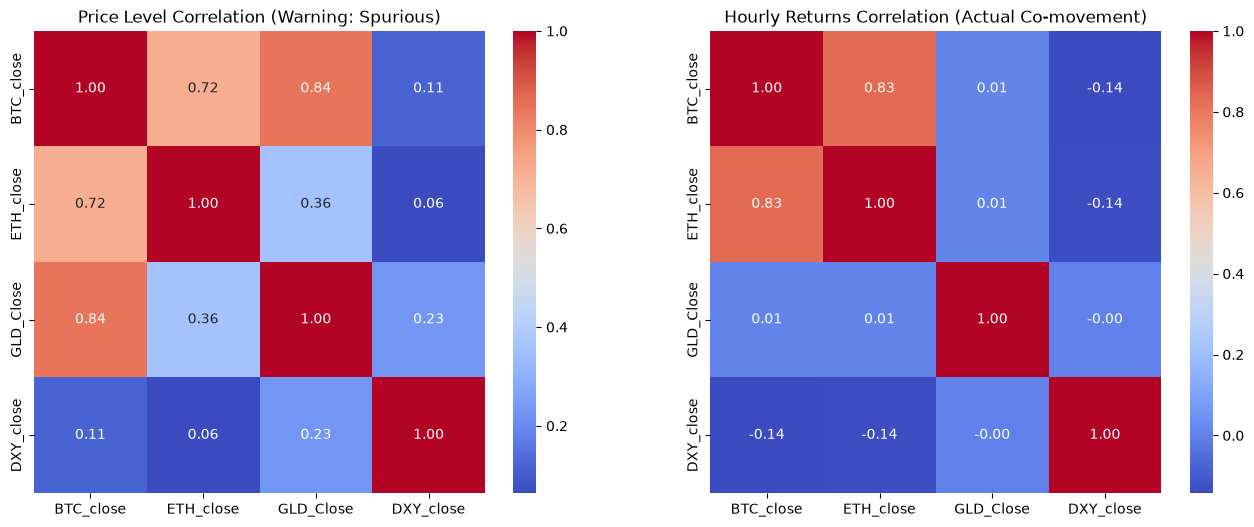

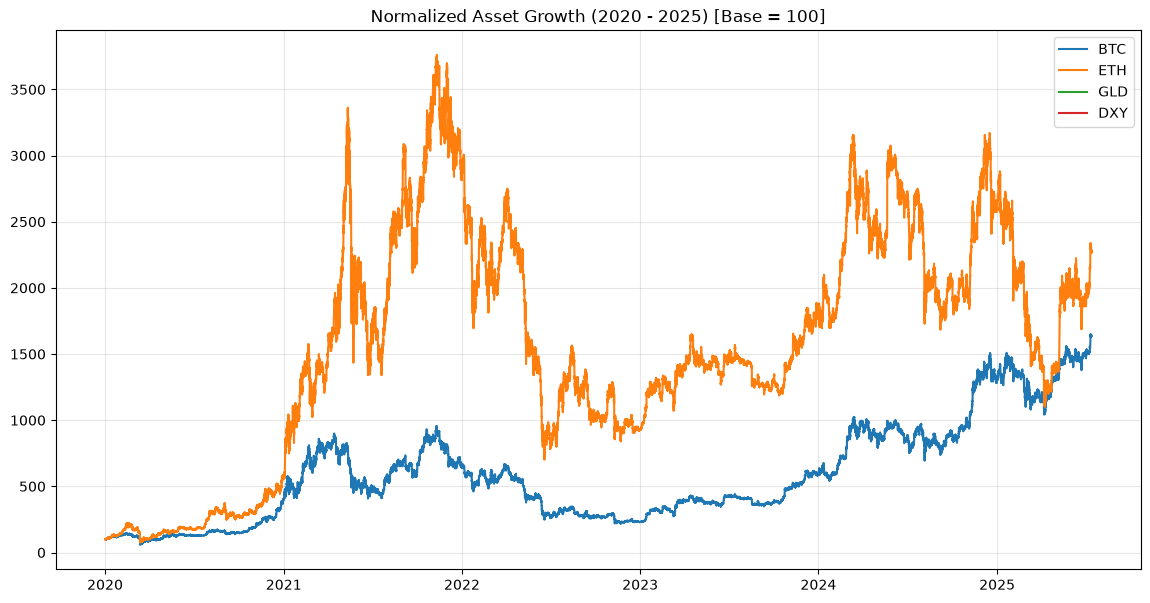

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Clean කරපු Data එක Load කිරීම
processed_path = r"E:\Innovus\Documents\Agentic-AI-Based-Market-Intelligence-Framework-For-Bitcoin-and-Ethereum-Trading\Vibhu Kalpitha\data\02_processed\macro_cleaned_1h.csv"
df = pd.read_csv(processed_path)
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# 2. Correlation Heatmaps (Price vs Returns)
price_cols = ['BTC_close', 'ETH_close', 'GLD_Close', 'DXY_close']
corr_prices = df[price_cols].corr()
corr_returns = df[price_cols].pct_change().dropna().corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_prices, annot=True, cmap='coolwarm', ax=axes[0], fmt=".2f")
axes[0].set_title("Price Level Correlation (Warning: Spurious)")

sns.heatmap(corr_returns, annot=True, cmap='coolwarm', ax=axes[1], fmt=".2f")
axes[1].set_title("Hourly Returns Correlation (Actual Co-movement)")
plt.show()

# 3. Normalized Price Trends Plot
normalized_prices = (df[price_cols] / df[price_cols].iloc[0]) * 100
plt.figure(figsize=(14, 7))
for col in price_cols:
    plt.plot(normalized_prices.index, normalized_prices[col], label=col.replace('_close', '').replace('_Close', ''))
plt.title("Normalized Asset Growth (2020 - 2025) [Base = 100]")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()